# Chapter 4: Representing Data and Engineering Features

## Chapter Summary
Models operate on numeric representations, so feature design can matter more than model choice. This chapter covers categorical encoding, discretization, interactions, polynomial expansion, nonlinear transformations, feature selection, and the use of domain knowledge.

## Theoretical Deep-Dive

One-hot encoding creates one indicator per category without inventing an order. Binning converts continuous values into intervals and can give linear models nonlinear stepwise behavior. Polynomial features add powers and interactions, allowing a linear estimator to fit curved surfaces while remaining linear in its coefficients.

Transformations such as $\log(1+x)$ can make skewed distributions easier to model. Feature selection reduces noise and complexity: univariate methods score features independently, model-based methods use learned importance, and iterative methods repeatedly fit a model.

All learned transformations belong inside the train/validation workflow to prevent leakage.

**Book coverage:** categorical variables, binning, polynomial/interactions, transformations, selection, and expert features (Chapter 4, printed pp. 211-250).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

customers = pd.DataFrame({
    "age": [22, 45, 36, 52, 29, 41, 63, 34, 27, 58, 47, 31],
    "income": [32, 85, 58, 95, 45, 72, 110, 54, 39, 99, 78, 49],
    "city": ["Jakarta", "Bandung", "Jakarta", "Surabaya", "Bandung", "Jakarta", "Surabaya", "Bandung", "Jakarta", "Surabaya", "Bandung", "Jakarta"],
    "premium": [0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0],
})
X = customers.drop(columns="premium"); y = customers["premium"]
preprocess = ColumnTransformer([
    ("numeric", StandardScaler(), ["age", "income"]),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), ["city"]),
])
encoded = preprocess.fit_transform(X)
print("Original shape:", X.shape, "Encoded shape:", encoded.shape)
print("Features:", preprocess.get_feature_names_out())

Original shape: (12, 3) Encoded shape: (12, 5)
Features: ['numeric__age' 'numeric__income' 'categorical__city_Bandung'
 'categorical__city_Jakarta' 'categorical__city_Surabaya']


linear               RMSE=6.317
binned               RMSE=3.594
polynomial degree 3  RMSE=1.855


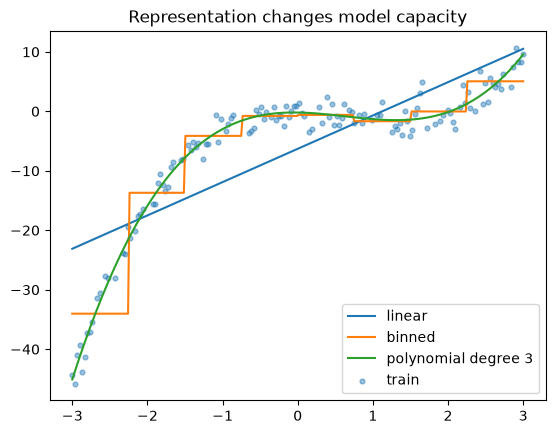

In [2]:
from sklearn.datasets import make_regression
from sklearn.preprocessing import KBinsDiscretizer, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(42)
x = np.linspace(-3, 3, 180).reshape(-1, 1)
y_curve = x[:, 0] ** 3 - 2 * x[:, 0] ** 2 + rng.normal(0, 2, len(x))
Xtr, Xte, ytr, yte = train_test_split(x, y_curve, random_state=42)

models = {
    "linear": LinearRegression(),
    "binned": make_pipeline(KBinsDiscretizer(n_bins=8, encode="onehot-dense", strategy="uniform"), LinearRegression()),
    "polynomial degree 3": make_pipeline(PolynomialFeatures(degree=3, include_bias=False), LinearRegression()),
}
grid = np.linspace(-3, 3, 300).reshape(-1, 1)
for name, model in models.items():
    model.fit(Xtr, ytr)
    print(f"{name:20s} RMSE={mean_squared_error(yte, model.predict(Xte)) ** 0.5:.3f}")
    plt.plot(grid, model.predict(grid), label=name)
plt.scatter(Xtr, ytr, s=12, alpha=0.45, label="train")
plt.legend(); plt.title("Representation changes model capacity"); plt.show()

In [3]:
from sklearn.datasets import load_breast_cancer
from sklearn.feature_selection import SelectPercentile, SelectFromModel, RFE
from sklearn.ensemble import RandomForestClassifier

data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, stratify=data.target, random_state=42)
selectors = {
    "univariate 40%": SelectPercentile(percentile=40),
    "model-based": SelectFromModel(RandomForestClassifier(n_estimators=100, random_state=42), threshold="median"),
    "recursive (12)": RFE(LogisticRegression(max_iter=3000), n_features_to_select=12, step=0.2),
}
selection_rows = []
for name, selector in selectors.items():
    pipe = make_pipeline(StandardScaler(), selector, LogisticRegression(max_iter=3000))
    pipe.fit(X_train, y_train)
    selection_rows.append((name, selector.fit(X_train, y_train).get_support().sum(), pipe.score(X_test, y_test)))
display(pd.DataFrame(selection_rows, columns=["method", "selected_features", "test_accuracy"]).round(3))

,method,selected_features,test_accuracy
0,univariate 40%,12,0.951
1,model-based,15,0.972
2,recursive (12),12,0.895


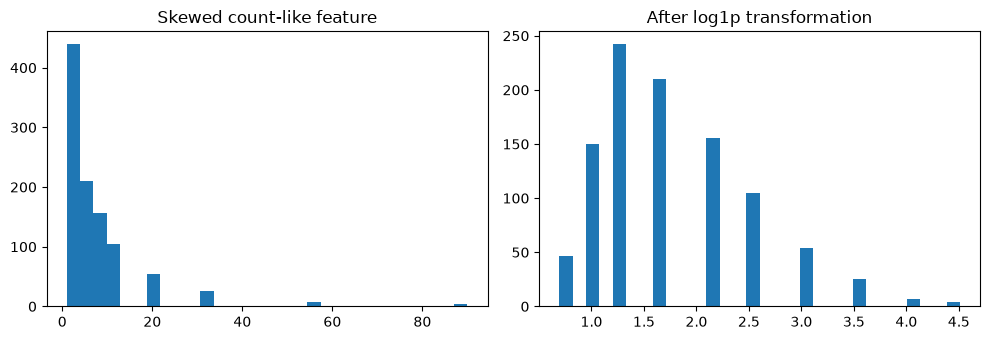

,age,income,income_per_age
0,22,32,1.454545
1,45,85,1.888889
2,36,58,1.611111
3,52,95,1.826923
4,29,45,1.551724


In [4]:
counts = rng.poisson(lam=3, size=1000)
skewed = np.exp(counts / 2)
transformed = np.log1p(skewed)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(skewed, bins=30); axes[0].set_title("Skewed count-like feature")
axes[1].hist(transformed, bins=30); axes[1].set_title("After log1p transformation")
plt.tight_layout(); plt.show()

customers["income_per_age"] = customers["income"] / customers["age"]
display(customers[["age", "income", "income_per_age"]].head())

## Key Takeaways
- Categorical codes are not numbers with meaningful distances; one-hot encode nominal categories.
- Binning and polynomial interactions change what a linear model can express.
- Transform highly skewed features when the model benefits from a more regular scale.
- Feature selection must be fitted inside each training fold.
- Domain-informed features can expose useful relationships unavailable to a generic algorithm.